# Cosmic Web 

## 1. Import and Setting

In [1]:
from dataclasses import replace
from pathlib import Path
from IPython.display import display, Image

from utils import (
    VizConfig, load_filaments, load_galaxies, add_sdss_xyz,
    attach_filament_associations, add_verified_galaxy_names,
    show_counts, render_galaxy_filament_2d,
    render_galaxy_filament_plotly, export_galaxy_filament_network,
    load_cmb, render_cmb_plotly, render_cmb_static
)

cfg = VizConfig(
    data_dir=Path("data"), output_dir=Path("outputs"),
    width=1920, height=1080, hubble_h=0.674,
    show_cmb_backdrop=True, cmb_source="WMAP9",
    cmb_colorscale="Turbo", cmb_backdrop_alpha=0.13,
    show_illustrative_cmb_shell_3d=True, cmb_shell_opacity=0.16,
    show_local_window=True, local_window_width_mly=350,
    show_scale_guide=True, show_title=True, galaxy_labels=True,
    max_galaxies_3d=35000, max_3d_filaments=0,
)

## 2. Load Data

In [2]:
required = [cfg.filament_csv, cfg.galaxy_csv]
if cfg.show_cmb_backdrop or cfg.show_illustrative_cmb_shell_3d or MAKE_STANDALONE_CMB:
    required.append(cfg.wmap_fits if cfg.cmb_source == "WMAP9" else cfg.planck_fits)
missing = [str(p.resolve()) for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError("Missing LOCAL datasets (no downloads attempted):\n" + "\n".join(missing))

filaments = load_filaments(cfg.filament_csv, require_full=cfg.strict_full_catalog)
galaxies = load_galaxies(cfg.galaxy_csv, require_full=cfg.strict_full_catalog)
galaxies = add_sdss_xyz(galaxies)
galaxies = attach_filament_associations(
    galaxies, filaments, max_dfil=cfg.max_galaxy_filament_distance
)
galaxies = add_verified_galaxy_names(galaxies, cfg.galaxy_names_csv)
for k, v in show_counts(galaxies, galaxies).items():
    print(f"{k}: {v:,}")

cmb_mk = load_cmb(cfg) if (cfg.show_cmb_backdrop or cfg.show_illustrative_cmb_shell_3d or MAKE_STANDALONE_CMB) else None

cataloged_galaxies_with_positions: 576,493
linked_nearest_filament_within_cutoff: 157,293
different_filaments_linked: 15,421


## 3. 2D cosmic web 

2D full survey: outputs\galaxy_filament_full_1920x1080.png


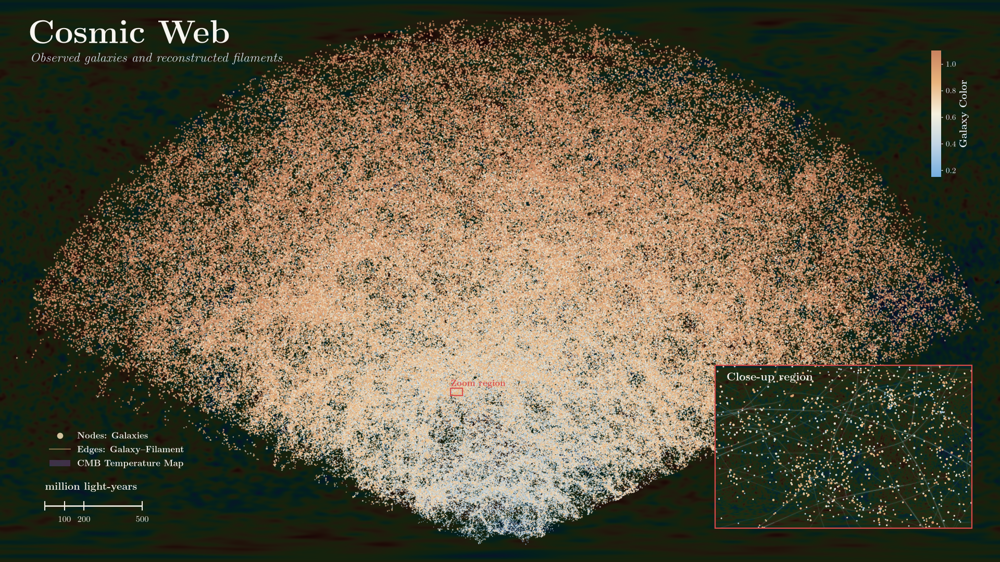

2D close-up: outputs\galaxy_filament_closeup_1920x1080.png


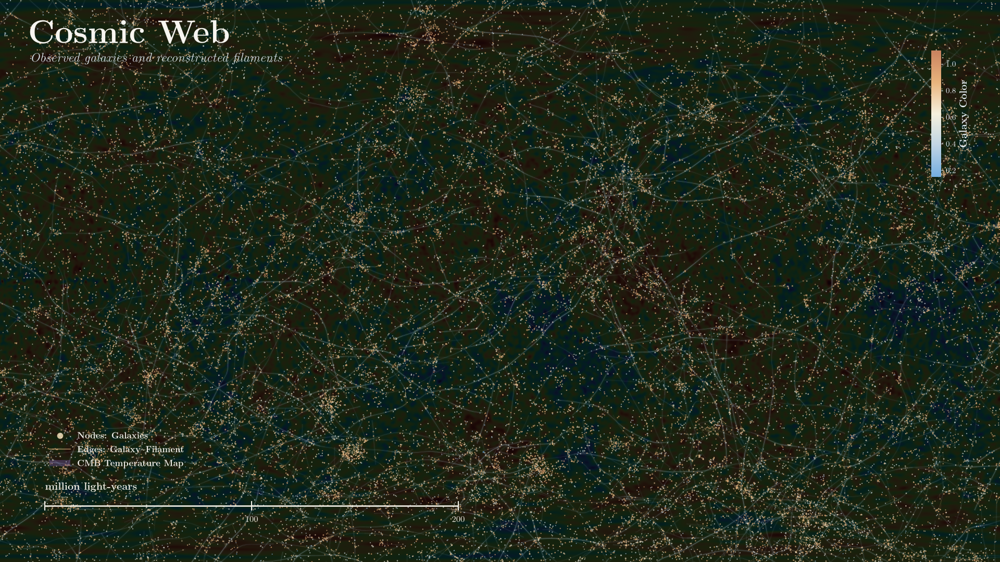

In [3]:
full_png = render_galaxy_filament_2d(galaxies, filaments, cfg, cmb_mk=cmb_mk)
print("2D full survey:", full_png)
display(Image(filename=str(full_png)))

close_cfg = replace(cfg, view_width_mpc_h=100.0, show_local_window=False)
close_png = render_galaxy_filament_2d(galaxies, filaments, close_cfg, cmb_mk=cmb_mk)
print("2D close-up:", close_png)
display(Image(filename=str(close_png)))

## 4. Interactive 3D network

3D galaxy network: outputs\galaxy_filament_network_3d.html


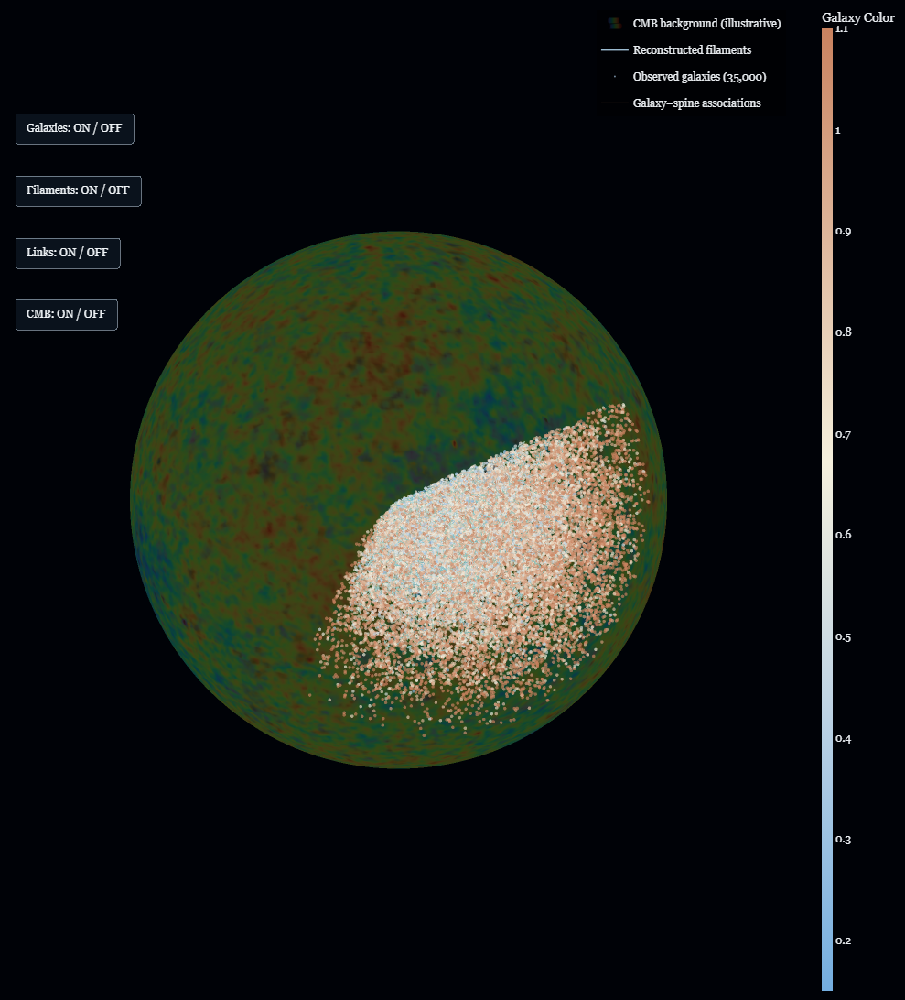

In [4]:
galaxy_html, galaxy_fig = render_galaxy_filament_plotly(
    galaxies, filaments, cfg, cmb_mk=cmb_mk, return_figure=True
)
print("3D galaxy network:", galaxy_html)
galaxy_fig.show()

## Data provenance and interpretation

- **Tempel et al. (2014)** [VizieR J/MNRAS/438/3465](https://cdsarc.cds.unistra.fr/viz-bin/cat/J/MNRAS/438/3465): galaxy observations and reconstructed filament spines.
- **NASA WMAP nine-year ILC** [LAMBDA](https://lambda.gsfc.nasa.gov/product/wmap/dr5/ilc_map_get.html): observed full-sky CMB temperature anisotropies. Optional local Planck SMICA FITS is supported.

## AI Usage

ChatGPT was used to acquire data, write the code to visualize, and debug errors.

